# Assignment 3: Time-Series Temperature Forecasting Using Deep Learning

### A Comparative Analysis of GRU, Stacked GRU, LSTM, and Conv1D-GRU Models Using the Jena Climate Dataset

## 1. Introduction

This assignment focuses on predicting future temperatures using the Jena Climate dataset and recurrent neural networks. The main objective is to predict the temperature 24 hours ahead using weather observations from the previous five days.

Different deep-learning models, including GRU, LSTM, stacked recurrent networks, and a combination of Conv1D and GRU, are developed and compared to identify which approach provides the most accurate predictions.

All models use the same training, validation, and testing datasets to ensure a fair comparison. Their performance is measured using Mean Absolute Error (MAE). A simple baseline model is also included to determine whether the neural networks improve forecasting accuracy. The best-performing model is selected using validation MAE and then evaluated on the test dataset.

In [3]:

# ==========================================================
# Assignment 3: Weather Time-Series Forecasting
# Step 1: Import the required Python libraries
# ==========================================================

import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Set a random seed to improve reproducibility
forecast_seed = 42

random.seed(forecast_seed)
np.random.seed(forecast_seed)
tf.random.set_seed(forecast_seed)

# Display the installed TensorFlow version
print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")


TensorFlow version: 2.21.0
Libraries imported successfully.


## 2. Dataset Description and Exploration

This assignment uses the Jena Climate dataset, which contains weather measurements recorded in Jena, Germany, every 10 minutes. The dataset includes 420,551 observations and 15 columns, consisting of date and time information and 14 weather-related variables.

Before building the forecasting models, the dataset was checked for missing values and explored to understand how temperature changes over time. A line graph was created to show temperature variations during the first ten days of January 2009.

In [4]:

# ==========================================================
# Step 2B: Download and load the Jena weather dataset
# ==========================================================

import zipfile

# Download the original compressed weather dataset
weather_file = keras.utils.get_file(
    fname="jena_climate_2009_2016.csv.zip",
    origin="https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
)

# Read the CSV directly from the ZIP file
with zipfile.ZipFile(weather_file, "r") as weather_archive:
    with weather_archive.open("jena_climate_2009_2016.csv") as csv_file:
        climate_records = pd.read_csv(csv_file)

# Display dataset information
print("Dataset shape:", climate_records.shape)

print("\nFirst five observations:")
display(climate_records.head())

# Check for missing values
print("\nMissing values by column:")
print(climate_records.isnull().sum())


13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset shape: (420551, 15)

First five observations:


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3



Missing values by column:
Date Time          0
p (mbar)           0
T (degC)           0
Tpot (K)           0
Tdew (degC)        0
rh (%)             0
VPmax (mbar)       0
VPact (mbar)       0
VPdef (mbar)       0
sh (g/kg)          0
H2OC (mmol/mol)    0
rho (g/m**3)       0
wv (m/s)           0
max. wv (m/s)      0
wd (deg)           0
dtype: int64


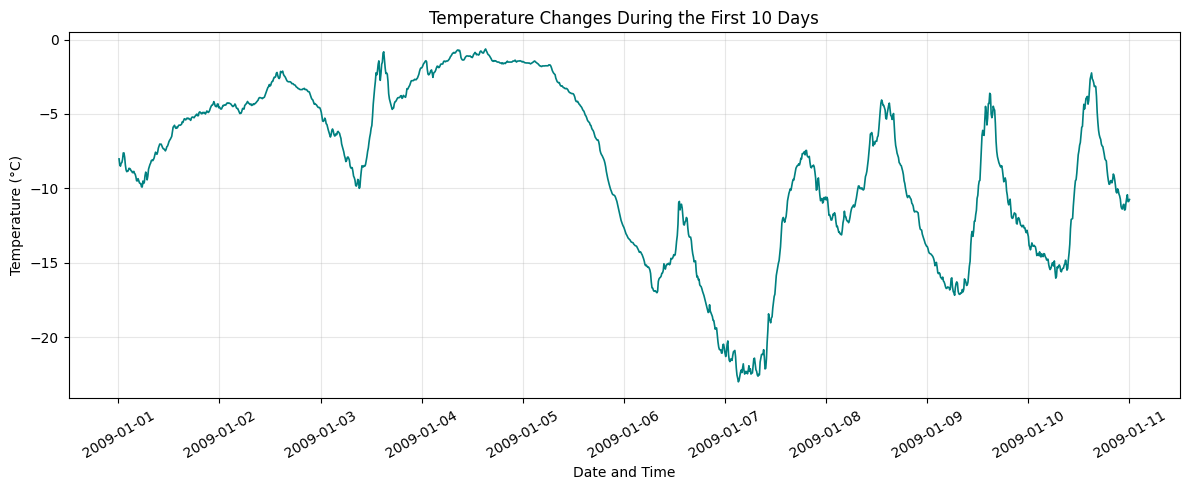

In [5]:

# ==========================================================
# Step 2C: Visualize temperature changes over 10 days
# ==========================================================

# Convert the date column to datetime format
climate_records["Date Time"] = pd.to_datetime(
    climate_records["Date Time"],
    format="%d.%m.%Y %H:%M:%S"
)

# Select the first 10 days of observations
weather_preview = climate_records.iloc[:1440]

# Plot the temperature measurements
plt.figure(figsize=(12, 5))

plt.plot(
    weather_preview["Date Time"],
    weather_preview["T (degC)"],
    color="teal",
    linewidth=1.2
)

plt.title("Temperature Changes During the First 10 Days")
plt.xlabel("Date and Time")
plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### Exploratory Data Analysis

The dataset contains no missing values across the recorded variables. During the first ten days of January 2009, temperatures varied between approximately −23°C and 0°C, with a noticeable drop around January 6–7.

The graph shows that temperature can change significantly over a short period. These variations highlight the importance of considering past weather conditions when predicting future temperatures. GRU and LSTM models will be used to examine how well these patterns can be learned.

## 3. Data Preparation and Normalization

The dataset was divided into three parts in time order: 50% for training, 25% for validation, and 25% for testing. This helps ensure that future observations are not used to train the models. The 14 weather variables were standardized using the mean and standard deviation calculated from the training data.

For forecasting, each input sequence contains 120 hourly observations, representing five days of weather data. The goal is to predict the temperature 24 hours after the last observation in each sequence. The same input structure and prediction period are used for all models to ensure a fair comparison.

In [6]:

# ==========================================================
# Step 3B: Prepare and standardize weather measurements
# ==========================================================

# Separate numerical weather measurements from timestamps
weather_features = climate_records.drop(
    columns=["Date Time"]
).astype("float32")

# Keep the original temperature values for forecasting targets
temperature_targets = weather_features["T (degC)"].to_numpy()

# Define chronological dataset boundaries
total_records = len(weather_features)

training_end = int(total_records * 0.50)
validation_end = int(total_records * 0.75)

# Calculate normalization statistics from training data only
training_mean = weather_features.iloc[:training_end].mean()
training_std = weather_features.iloc[:training_end].std()

# Prevent division by zero for any constant feature
training_std = training_std.replace(0, 1)

# Standardize all numerical weather features
scaled_weather = (
    (weather_features - training_mean) / training_std
).to_numpy(dtype="float32")

# Display the dataset sizes
print("Training records:", training_end)
print("Validation records:", validation_end - training_end)
print("Testing records:", total_records - validation_end)

print("\nNumber of weather features:", scaled_weather.shape[1])
print("Normalized data shape:", scaled_weather.shape)


Training records: 210275
Validation records: 105138
Testing records: 105138

Number of weather features: 14
Normalized data shape: (420551, 14)


In [7]:

# ==========================================================
# Step 3C: Generate Time-Series Forecasting Sequences
# ==========================================================

# Define the forecasting settings
hourly_sampling = 6
history_window = 120
forecast_hours = 24
forecast_batch = 256

# Calculate the future temperature target position
prediction_offset = hourly_sampling * (
    history_window + forecast_hours - 1
)

# Function to create historical weather sequences
def build_weather_sequences(start_row, end_row, shuffle_data=False):

    # Select future temperature values as prediction targets
    forecast_targets = temperature_targets[
        start_row + prediction_offset:end_row
    ]

    # Create sequences from standardized weather measurements
    return keras.utils.timeseries_dataset_from_array(
        data=scaled_weather[start_row:end_row],
        targets=forecast_targets,
        sequence_length=history_window,
        sampling_rate=hourly_sampling,
        sequence_stride=1,
        shuffle=shuffle_data,
        batch_size=forecast_batch,
        seed=forecast_seed if shuffle_data else None
    )

# Create the three chronological datasets
training_series = build_weather_sequences(
    0, training_end, shuffle_data=True
)

validation_series = build_weather_sequences(
    training_end, validation_end
)

testing_series = build_weather_sequences(
    validation_end, total_records
)

# Verify that the datasets are ready
print("Training dataset created successfully.")
print("Validation dataset created successfully.")
print("Testing dataset created successfully.")

# Display the dimensions of one training batch
for weather_batch, target_batch in training_series.take(1):
    print("\nInput batch shape:", weather_batch.shape)
    print("Target batch shape:", target_batch.shape)


Training dataset created successfully.
Validation dataset created successfully.
Testing dataset created successfully.

Input batch shape: (256, 120, 14)
Target batch shape: (256,)


For this experiment, I used 120 hourly observations to study past weather conditions. Since the original dataset records measurements every 10 minutes, I selected every sixth observation to represent hourly data. The model uses these past observations to predict the temperature 24 hours after the final observation in the input sequence. This allows me to examine how well recurrent neural networks can forecast future temperatures using historical weather patterns.

### Prepared Data Structure

After dividing the dataset, 210,275 observations were used for training, 105,138 for validation, and 105,138 for testing.

The generated sequences have an input shape of `(256, 120, 14)`, representing 256 sequences per batch, 120 hourly observations, and 14 weather features. Each sequence is paired with one future temperature value, giving the target batch a shape of `(256,)`.

The temperature values used for prediction remain in degrees Celsius, making the model results easier to interpret and compare.

## 4. Persistence Forecasting Baseline

A simple baseline model was used to provide a starting point for comparing the forecasting models. This method predicts that the temperature 24 hours ahead will be the same as the last observed temperature in each input sequence.

The baseline model's accuracy was measured using validation Mean Absolute Error (MAE) in degrees Celsius. Its result will be compared with the GRU, LSTM, and other neural network models to determine whether they provide more accurate temperature predictions.

In [8]:

# ==========================================================
# Step 4B: Calculate Baseline Validation MAE
# ==========================================================

# Identify the temperature feature
temperature_position = weather_features.columns.get_loc("T (degC)")

# Retrieve temperature standardization statistics
temperature_mean = float(training_mean["T (degC)"])
temperature_std = float(training_std["T (degC)"])

# Function to evaluate baseline predictions
def calculate_baseline_mae(weather_dataset):

    total_absolute_error = 0.0
    total_predictions = 0

    for weather_inputs, actual_temperatures in weather_dataset:

        # Predict future temperature using the last observed value
        last_observed_temp = weather_inputs[:, -1, temperature_position]

        # Convert normalized temperature back to Celsius
        predicted_temperatures = (
            last_observed_temp * temperature_std + temperature_mean
        )

        # Calculate absolute errors
        absolute_errors = tf.abs(
            actual_temperatures - predicted_temperatures
        )

        total_absolute_error += float(
            tf.reduce_sum(absolute_errors)
        )

        total_predictions += int(tf.size(absolute_errors))

    return total_absolute_error / total_predictions

# Calculate validation MAE
baseline_validation_mae = calculate_baseline_mae(validation_series)

print(f"Baseline Validation MAE: {baseline_validation_mae:.3f} °C")


Baseline Validation MAE: 2.443 °C


### Interpretation of Baseline Results

The baseline model achieved a validation MAE of **2.443°C**, meaning its predicted temperatures differed from the actual values by approximately 2.44°C on average.

This result provides a reference for comparing the deep-learning models. The GRU, LSTM, and hybrid models will be evaluated to determine whether they can achieve a lower validation MAE and improve temperature prediction accuracy.

## 5. GRU-Based Weather Forecasting Model

The first deep-learning model uses a Gated Recurrent Unit (GRU) to predict temperature 24 hours ahead based on previous weather observations.

The model consists of a single GRU layer with 32 units, followed by a dense output layer that produces the temperature prediction. Mean squared error (MSE) is used as the loss function, while mean absolute error (MAE) is used to evaluate prediction accuracy. The model uses the RMSprop optimizer with a learning rate of 0.001.

The GRU model will be trained on the training dataset and evaluated using validation MAE. Its performance will then be compared with the baseline result of 2.443°C to determine whether it improves forecasting accuracy.

In [9]:

# ==========================================================
# Step 5B: Build the First GRU Forecasting Model
# ==========================================================

# Create a single-layer GRU model
basic_gru_model = keras.Sequential([
    layers.Input(shape=(history_window, scaled_weather.shape[1])),

    # GRU layer learns relationships across weather observations
    layers.GRU(32),

    # Dense layer predicts the future temperature
    layers.Dense(1)
])

# Configure the model for training
basic_gru_model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display the neural network architecture
basic_gru_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,641 (18.13 KB)

 Trainable params: 4,641 (18.13 KB)

 Non-trainable params: 0 (0.00 B)

### GRU Model Architecture

The GRU model contains 32 recurrent units followed by a dense layer with one output neuron for temperature prediction. It has 4,641 trainable parameters. This architecture is designed to learn patterns from past weather observations and use them to predict future temperatures.

### GRU Model Training

The GRU model is trained using the prepared weather sequences, with validation MAE used to monitor its performance. Early stopping is applied to reduce unnecessary training and restore the model weights from the best-performing epoch.

In [11]:

# Step 5C: GRU Model Training

# Stop training when validation MAE stops improving
gru_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_mae",
    patience=3,
    restore_best_weights=True
)

# Train the GRU model
gru_training_history = basic_gru_model.fit(
    training_series,
    validation_data=validation_series,
    epochs=15,
    callbacks=[gru_early_stopping],
    verbose=1
)

# Record the best validation MAE
best_gru_validation_mae = min(
    gru_training_history.history["val_mae"]
)

print(f"Best GRU Validation MAE: {best_gru_validation_mae:.3f} °C")


Epoch 1/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 45s 53ms/step - loss: 24.0265 - mae: 3.4952 - val_loss: 9.2853 - val_mae: 2.3757
Epoch 2/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 42s 51ms/step - loss: 9.3446 - mae: 2.3866 - val_loss: 9.3580 - val_mae: 2.3731
Epoch 3/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 81s 50ms/step - loss: 8.8795 - mae: 2.3252 - val_loss: 9.4792 - val_mae: 2.3643
Epoch 4/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 40s 49ms/step - loss: 8.4221 - mae: 2.2695 - val_loss: 9.9133 - val_mae: 2.4188
Epoch 5/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 41s 50ms/step - loss: 7.9750 - mae: 2.2115 - val_loss: 9.9369 - val_mae: 2.4297
Epoch 6/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 40s 49ms/step - loss: 7.5879 - mae: 2.1561 - val_loss: 10.3556 - val_mae: 2.4992
Best GRU Validation MAE: 2.364 °C


### GRU Training Results and Interpretation

The GRU model achieved its lowest validation MAE of **2.364°C** during the third epoch, improving upon the baseline MAE of 2.443°C. Training stopped after six epochs because validation performance did not improve for three consecutive epochs.

Although the training error continued to decrease, the validation error increased after the third epoch, suggesting that the model began to overfit the training data. Early stopping helped address this by restoring the weights from the best-performing epoch.

Overall, the GRU model provided a modest improvement over the baseline and will be compared with the other forecasting models.

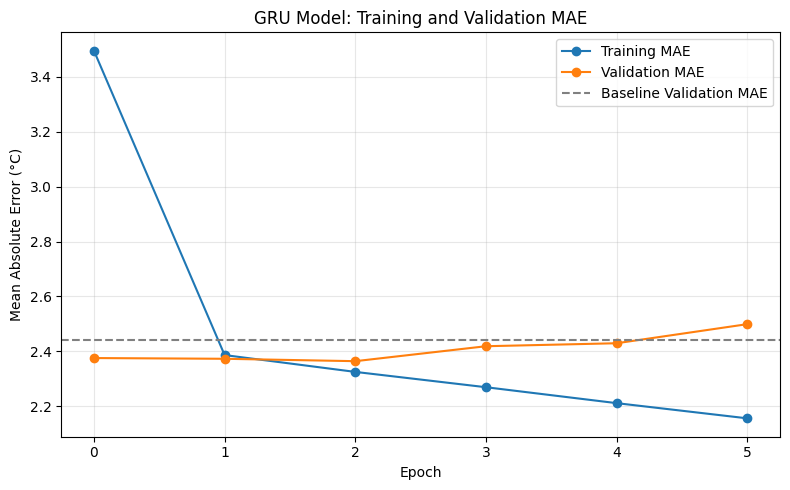

In [12]:

# Step 5D: Visualize GRU Training Performance

plt.figure(figsize=(8, 5))

plt.plot(
    gru_training_history.history["mae"],
    label="Training MAE",
    marker="o"
)

plt.plot(
    gru_training_history.history["val_mae"],
    label="Validation MAE",
    marker="o"
)

plt.axhline(
    y=baseline_validation_mae,
    linestyle="--",
    color="gray",
    label="Baseline Validation MAE"
)

plt.title("GRU Model: Training and Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### GRU Training Performance

The graph shows that training MAE decreased throughout the six epochs. However, validation MAE reached its lowest value of 2.364°C during the third epoch and then started increasing.

This suggests that the model may have started fitting the training data too closely instead of improving its predictions on unseen data. Early stopping helped address this by restoring the weights from the third epoch, when validation performance was best. The GRU also performed slightly better than the baseline MAE of 2.443°C.

## 6. Improving the GRU Model

### GRU Model with 64 Units

To examine the effect of model size on forecasting accuracy, a second GRU model is developed using 64 recurrent units instead of 32. The remaining settings, including the input sequences, optimizer, and loss function, are kept the same to allow a fair comparison.

The new model will be evaluated using validation MAE to determine whether increasing the number of recurrent units improves temperature prediction accuracy.

In [13]:

# Step 6A: Build a GRU Model with 64 Units

gru_64_model = keras.Sequential([
    layers.Input(shape=(history_window, scaled_weather.shape[1])),
    layers.GRU(64),
    layers.Dense(1)
])

# Compile the model
gru_64_model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display the model architecture
gru_64_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                     │ (None, 64)             │        15,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,425 (60.25 KB)

 Trainable params: 15,425 (60.25 KB)

 Non-trainable params: 0 (0.00 B)

### Training the 64-Unit GRU Model

The 64-unit GRU model is trained using the same dataset, optimizer, and training settings as the original GRU model. Early stopping is used to monitor validation MAE and restore the weights from the best-performing epoch. This allows the two models to be compared under consistent conditions.

In [14]:

# Step 6B: Train the 64-Unit GRU Model

# Apply early stopping
gru_64_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_mae",
    patience=3,
    restore_best_weights=True
)

# Train the model
gru_64_training_history = gru_64_model.fit(
    training_series,
    validation_data=validation_series,
    epochs=15,
    callbacks=[gru_64_early_stopping],
    verbose=1
)

# Record the best validation MAE
best_gru_64_validation_mae = min(
    gru_64_training_history.history["val_mae"]
)

print(
    f"Best 64-Unit GRU Validation MAE: "
    f"{best_gru_64_validation_mae:.3f} °C"
)


Epoch 1/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 44s 53ms/step - loss: 15.0897 - mae: 2.8666 - val_loss: 11.4656 - val_mae: 2.6657
Epoch 2/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 60ms/step - loss: 8.7147 - mae: 2.3097 - val_loss: 10.3413 - val_mae: 2.4670
Epoch 3/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 44s 54ms/step - loss: 7.7073 - mae: 2.1772 - val_loss: 8.9572 - val_mae: 2.3271
Epoch 4/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - loss: 6.6758 - mae: 2.0293 - val_loss: 9.4862 - val_mae: 2.3912
Epoch 5/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 42s 51ms/step - loss: 5.6170 - mae: 1.8586 - val_loss: 11.8996 - val_mae: 2.6514
Epoch 6/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 42s 51ms/step - loss: 4.7416 - mae: 1.7023 - val_loss: 12.1633 - val_mae: 2.6935
Best 64-Unit GRU Validation MAE: 2.327 °C


### Results and Interpretation of the 64-Unit GRU Model

The 64-unit GRU model achieved its lowest validation MAE of **2.327°C** during the third epoch, compared with 2.364°C for the original 32-unit GRU model. This indicates that increasing the number of recurrent units provided a small improvement in forecasting accuracy.

Although training MAE continued to decrease, validation MAE increased after the third epoch, suggesting overfitting. Early stopping restored the weights from the best-performing epoch.

Overall, the 64-unit GRU model performed better than the original GRU model and the baseline forecast. However, the improvement was relatively small, showing that increasing model size does not necessarily lead to a substantial gain in accuracy.

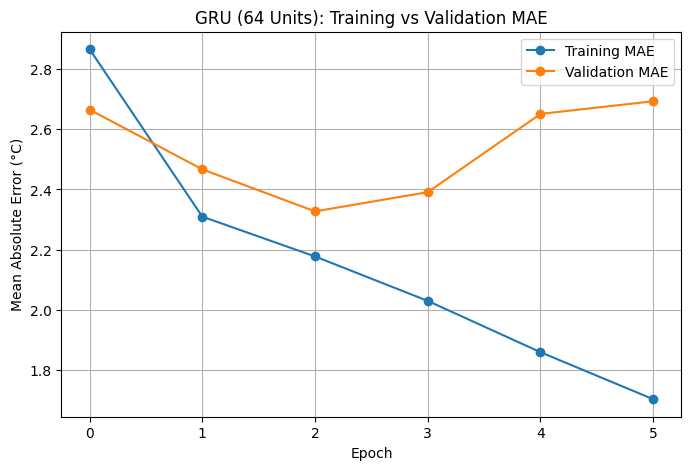

In [28]:

# Step 6C: GRU (64 Units) Training and Validation MAE

plt.figure(figsize=(8, 5))

plt.plot(
    gru_64_training_history.history["mae"],
    label="Training MAE",
    marker="o"
)

plt.plot(
    gru_64_training_history.history["val_mae"],
    label="Validation MAE",
    marker="o"
)

plt.title("GRU (64 Units): Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error (°C)")
plt.legend()
plt.grid(True)
plt.show()


### GRU (64 Units) Training Performance

The training MAE decreased steadily across six epochs, showing that the model continued learning from the training data. However, validation MAE reached its lowest value of approximately 2.327°C during the third epoch and increased afterward. This suggests that the model may have started overfitting the training data. Early stopping helped retain the model weights from the epoch with the best validation performance.

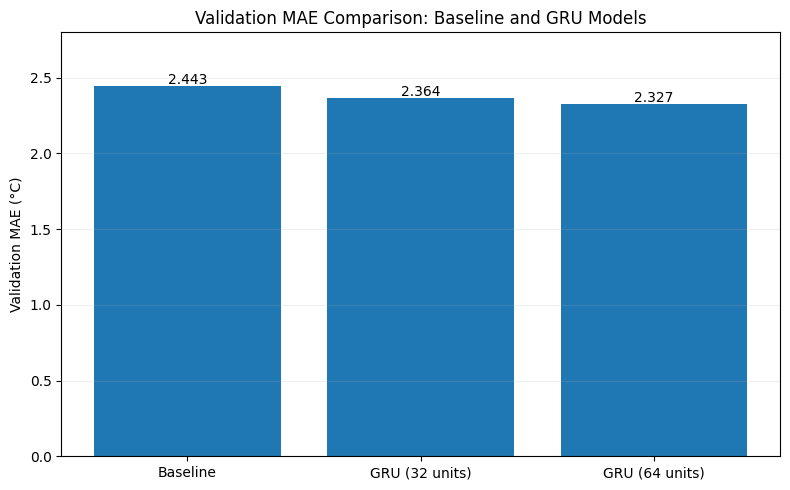

In [15]:

# Step 6D: Compare GRU Models Using Validation MAE

gru_model_names = [
    "Baseline",
    "GRU (32 units)",
    "GRU (64 units)"
]

gru_validation_scores = [
    baseline_validation_mae,
    best_gru_validation_mae,
    best_gru_64_validation_mae
]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    gru_model_names,
    gru_validation_scores
)

for bar, score in zip(bars, gru_validation_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.015,
        f"{score:.3f}",
        ha="center"
    )

plt.title("Validation MAE Comparison: Baseline and GRU Models")
plt.ylabel("Validation MAE (°C)")
plt.ylim(0, 2.8)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()


### GRU Model Comparison Interpretation

When I compared the two GRU models, I found that the 64-unit GRU performed slightly better than the 32-unit GRU. The 64-unit model achieved a validation MAE of 2.327°C, while the 32-unit model achieved 2.364°C. Both models performed better than the baseline of 2.443°C. This shows that increasing the number of GRU units helped improve forecasting accuracy in this experiment, although the difference was relatively small.

## 7. Stacked GRU Model

A stacked GRU model is developed to examine whether using multiple recurrent layers improves temperature forecasting. Unlike the previous models, which contain a single GRU layer, this model uses two GRU layers with 32 units each.

The first GRU layer passes its sequence of outputs to the second layer, allowing the network to learn more complex patterns from historical weather data. The model is evaluated using the same training and validation datasets as the earlier models.

In [16]:

# Step 7A: Build a Stacked GRU Model

stacked_gru_model = keras.Sequential([
    layers.Input(shape=(history_window, scaled_weather.shape[1])),
    layers.GRU(32, return_sequences=True),
    layers.GRU(32),
    layers.Dense(1)
])

# Compile the stacked GRU model
stacked_gru_model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display the model architecture
stacked_gru_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 120, 32)        │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,977 (42.88 KB)

 Trainable params: 10,977 (42.88 KB)

 Non-trainable params: 0 (0.00 B)

### Training the Stacked GRU Model

The stacked GRU model is trained using the same weather sequences and training settings as the previous models. Validation MAE is monitored throughout training, and early stopping is used to restore the weights from the best-performing epoch. The results will help determine whether adding a second GRU layer improves forecasting accuracy.

In [17]:

# Step 7B: Train the Stacked GRU Model

stacked_gru_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_mae",
    patience=3,
    restore_best_weights=True
)

stacked_gru_training_history = stacked_gru_model.fit(
    training_series,
    validation_data=validation_series,
    epochs=15,
    callbacks=[stacked_gru_early_stopping],
    verbose=1
)

# Record the best validation MAE
best_stacked_gru_validation_mae = min(
    stacked_gru_training_history.history["val_mae"]
)

print(
    f"Best Stacked GRU Validation MAE: "
    f"{best_stacked_gru_validation_mae:.3f} °C"
)


Epoch 1/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - loss: 19.6545 - mae: 3.2027 - val_loss: 8.9528 - val_mae: 2.3176
Epoch 2/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 45s 55ms/step - loss: 8.9179 - mae: 2.3364 - val_loss: 9.7854 - val_mae: 2.4587
Epoch 3/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 45s 54ms/step - loss: 7.9314 - mae: 2.2145 - val_loss: 10.2906 - val_mae: 2.5087
Epoch 4/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 82s 54ms/step - loss: 7.0407 - mae: 2.0898 - val_loss: 11.1469 - val_mae: 2.6265
Best Stacked GRU Validation MAE: 2.318 °C


### Stacked GRU Results and Interpretation

The stacked GRU model achieved its lowest validation MAE of **2.318°C** during the first epoch, slightly improving upon the 64-unit GRU model's result of 2.327°C.

Although training MAE continued to decrease, validation MAE increased in the following epochs, suggesting that the model began to overfit the training data. Early stopping restored the weights from the first epoch.

The results indicate that adding a second GRU layer provided a small improvement in forecasting accuracy. Among the models evaluated so far, the stacked GRU achieved the lowest validation MAE.

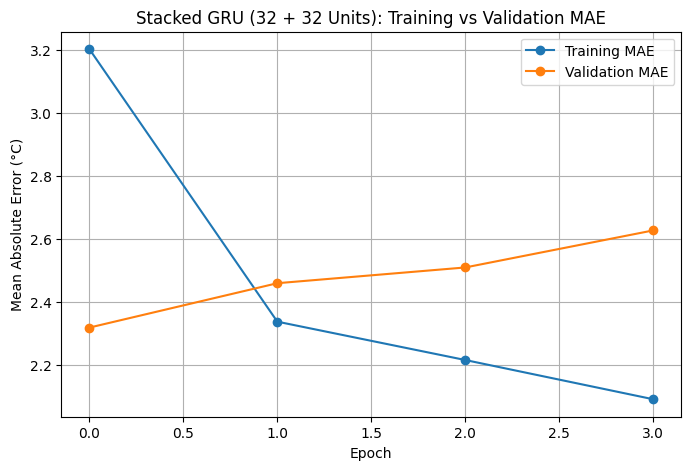

In [29]:

# Step 7C: Stacked GRU Training and Validation MAE

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    stacked_gru_training_history.history["mae"],
    label="Training MAE",
    marker="o"
)

plt.plot(
    stacked_gru_training_history.history["val_mae"],
    label="Validation MAE",
    marker="o"
)

plt.title("Stacked GRU (32 + 32 Units): Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error (°C)")
plt.legend()
plt.grid(True)
plt.show()


### Stacked GRU Training Performance

The stacked GRU model achieved its lowest validation MAE of approximately 2.318°C during the first epoch. Although training MAE continued to decrease over the following epochs, validation MAE gradually increased. This suggests that the model may have started overfitting the training data.

Early stopping helped retain the model weights from the epoch with the lowest validation error. Among the models tested, the stacked GRU achieved the best validation performance, although its improvement over the 64-unit GRU was relatively small.

## 8. LSTM-Based Weather Forecasting Model

An LSTM model is developed to compare its forecasting performance with the GRU models. Like GRU, LSTM is designed to learn patterns from sequential data, but it uses a different gating mechanism to manage information over time.

The model consists of a single LSTM layer with 32 units followed by a dense output layer. The same input sequences, optimizer, loss function, and evaluation metric are used to ensure a consistent comparison between LSTM and GRU.

In [18]:

# Step 8A: Build the LSTM Weather Forecasting Model

lstm_32_model = keras.Sequential([
    layers.Input(shape=(history_window, scaled_weather.shape[1])),
    layers.LSTM(32),
    layers.Dense(1)
])

# Compile the LSTM model
lstm_32_model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display the model architecture
lstm_32_model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         6,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,049 (23.63 KB)

 Trainable params: 6,049 (23.63 KB)

 Non-trainable params: 0 (0.00 B)

### LSTM Model Training

The LSTM model is trained using the same weather sequences and training settings as the GRU models. Validation MAE is used to monitor prediction accuracy, while early stopping is applied to prevent unnecessary training and restore the weights from the best-performing epoch.

The results will be compared with the GRU models to evaluate whether LSTM provides better forecasting accuracy.

In [19]:

# Step 8B: Train the LSTM Model

# Apply early stopping
lstm_32_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_mae",
    patience=3,
    restore_best_weights=True
)

# Train the LSTM model
lstm_32_training_history = lstm_32_model.fit(
    training_series,
    validation_data=validation_series,
    epochs=15,
    callbacks=[lstm_32_early_stopping],
    verbose=1
)

# Record the best validation MAE
best_lstm_32_validation_mae = min(
    lstm_32_training_history.history["val_mae"]
)

print(
    f"Best LSTM Validation MAE: "
    f"{best_lstm_32_validation_mae:.3f} °C"
)


Epoch 1/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 44s 52ms/step - loss: 23.9797 - mae: 3.5045 - val_loss: 9.9462 - val_mae: 2.4472
Epoch 2/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 41s 50ms/step - loss: 9.3840 - mae: 2.3905 - val_loss: 10.3392 - val_mae: 2.5051
Epoch 3/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - loss: 8.4506 - mae: 2.2684 - val_loss: 10.3697 - val_mae: 2.5092
Epoch 4/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 41s 50ms/step - loss: 7.9039 - mae: 2.1910 - val_loss: 10.7939 - val_mae: 2.5714
Best LSTM Validation MAE: 2.447 °C


### LSTM Results and Interpretation

The LSTM model achieved its lowest validation MAE of 2.447°C during the first epoch. This was slightly higher than the persistence baseline of 2.443°C and also higher than the GRU models.

Although training MAE continued to decrease, validation MAE increased after the first epoch. This suggests possible overfitting, so early stopping restored the weights from the best epoch.

In this experiment, the GRU models performed better than the LSTM model. However, this does not mean LSTM is always less effective. The results only show that GRU worked better for this dataset and the settings used in this assignment.

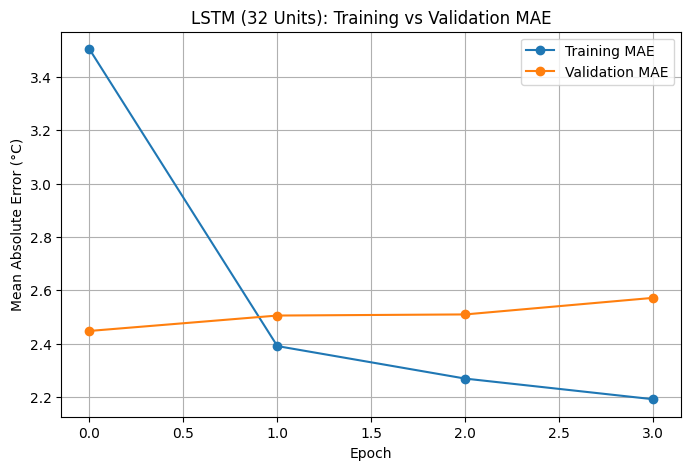

In [30]:

# Step 8C: LSTM Training and Validation MAE

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    lstm_32_training_history.history["mae"],
    label="Training MAE",
    marker="o"
)

plt.plot(
    lstm_32_training_history.history["val_mae"],
    label="Validation MAE",
    marker="o"
)

plt.title("LSTM (32 Units): Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error (°C)")
plt.legend()
plt.grid(True)
plt.show()


### LSTM (32 Units) Training Performance

The LSTM model achieved its lowest validation MAE of approximately 2.447°C during the first epoch. Although training MAE continued to decrease over the following epochs, validation MAE gradually increased. This suggests that the model may have started overfitting the training data.

Early stopping helped retain the model weights from the epoch with the lowest validation error. In this experiment, the LSTM performed slightly worse than the persistence baseline and did not outperform the GRU models.

## 9. Conv1D-GRU Hybrid Model

A hybrid model combining one-dimensional convolution (Conv1D) and GRU is developed to examine whether extracting short-term weather patterns before recurrent processing improves forecasting accuracy.

The Conv1D layer processes the input sequences to identify local patterns in weather measurements, while the GRU layer learns temporal relationships from the extracted features. The model is trained and evaluated using the same datasets and validation MAE metric as the previous models.

In [20]:

# Step 9A: Build the Conv1D-GRU Hybrid Model

conv_gru_model = keras.Sequential([
    layers.Input(shape=(history_window, scaled_weather.shape[1])),
    layers.Conv1D(
        filters=32,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),
    layers.GRU(32),
    layers.Dense(1)
])

# Compile the hybrid model
conv_gru_model.compile(
    optimizer=keras.optimizers.RMSprop(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Display the model architecture
conv_gru_model.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 120, 32)        │         1,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_4 (GRU)                     │ (None, 32)             │         6,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,745 (30.25 KB)

 Trainable params: 7,745 (30.25 KB)

 Non-trainable params: 0 (0.00 B)

### Conv1D-GRU Model Training

The Conv1D-GRU hybrid model is trained using the same weather sequences and training settings as the previous models. Validation MAE is monitored during training, and early stopping is used to restore the weights from the best-performing epoch.

The model's performance will be compared with the GRU and LSTM models to determine whether combining convolutional and recurrent layers improves forecasting accuracy.

In [21]:

# Step 9B: Train the Conv1D-GRU Hybrid Model

# Apply early stopping
conv_gru_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_mae",
    patience=3,
    restore_best_weights=True
)

# Train the hybrid model
conv_gru_training_history = conv_gru_model.fit(
    training_series,
    validation_data=validation_series,
    epochs=15,
    callbacks=[conv_gru_early_stopping],
    verbose=1
)

# Record the best validation MAE
best_conv_gru_validation_mae = min(
    conv_gru_training_history.history["val_mae"]
)

print(
    f"Best Conv1D-GRU Validation MAE: "
    f"{best_conv_gru_validation_mae:.3f} °C"
)


Epoch 1/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 43s 50ms/step - loss: 23.2021 - mae: 3.4384 - val_loss: 9.2142 - val_mae: 2.3447
Epoch 2/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 43s 52ms/step - loss: 9.2111 - mae: 2.3639 - val_loss: 9.1461 - val_mae: 2.3447
Epoch 3/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 43s 52ms/step - loss: 8.5095 - mae: 2.2705 - val_loss: 9.5377 - val_mae: 2.4070
Epoch 4/15
819/819 ━━━━━━━━━━━━━━━━━━━━ 42s 50ms/step - loss: 7.7827 - mae: 2.1755 - val_loss: 9.6850 - val_mae: 2.4213
Best Conv1D-GRU Validation MAE: 2.345 °C


### Conv1D-GRU Results and Interpretation

The Conv1D-GRU hybrid model achieved a best validation MAE of **2.345°C**, improving upon the baseline forecast of 2.443°C. However, its prediction error was slightly higher than that of the stacked GRU model, which achieved 2.318°C.

Training MAE decreased across the four epochs, while validation MAE increased after the initial epochs, suggesting possible overfitting. Early stopping helped retain the weights associated with the lowest validation error.

These results show that combining convolutional and recurrent layers provided reasonable forecasting accuracy, but it did not outperform the stacked GRU under the tested settings.

Overall, the stacked GRU remains the best-performing model based on validation MAE.

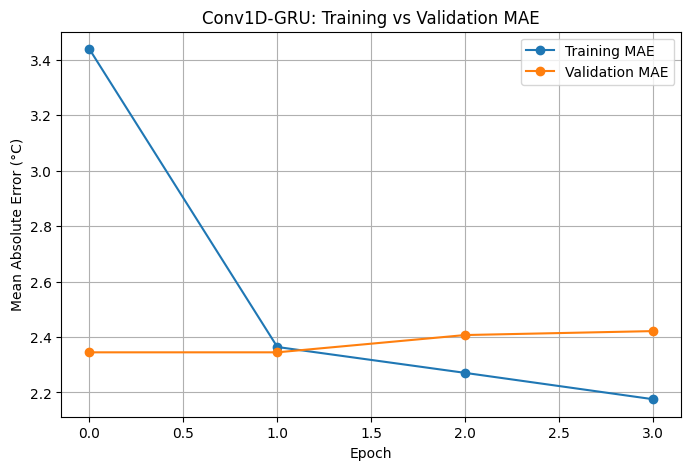

In [31]:

# Step 9C: Conv1D-GRU Training and Validation MAE

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    conv_gru_training_history.history["mae"],
    label="Training MAE",
    marker="o"
)

plt.plot(
    conv_gru_training_history.history["val_mae"],
    label="Validation MAE",
    marker="o"
)

plt.title("Conv1D-GRU: Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error (°C)")
plt.legend()
plt.grid(True)
plt.show()


### Conv1D-GRU Training Performance

The Conv1D-GRU model achieved its lowest validation MAE of approximately 2.345°C during the second epoch. Training MAE continued to decrease throughout the four epochs, while validation MAE increased slightly after the second epoch. This suggests that the model may have started overfitting the training data.

The combination of convolutional and recurrent layers performed better than the persistence baseline, but it did not outperform the stacked GRU. This shows that adding convolutional layers did not provide a significant advantage for this particular forecasting task.

## 10. Model Performance Comparison

The forecasting models are compared using their best validation Mean Absolute Error (MAE). All models were trained using the same weather dataset, input sequences, and evaluation metric to maintain consistency.

Lower validation MAE indicates better forecasting accuracy. The comparison includes the persistence baseline, the single-layer GRU models, the stacked GRU, the LSTM, and the Conv1D-GRU hybrid model.

,Model,Validation MAE (°C)
0,Stacked GRU (32 + 32),2.318
1,GRU (64 units),2.327
2,Conv1D-GRU,2.345
3,GRU (32 units),2.364
4,Persistence Baseline,2.443
5,LSTM (32 units),2.447


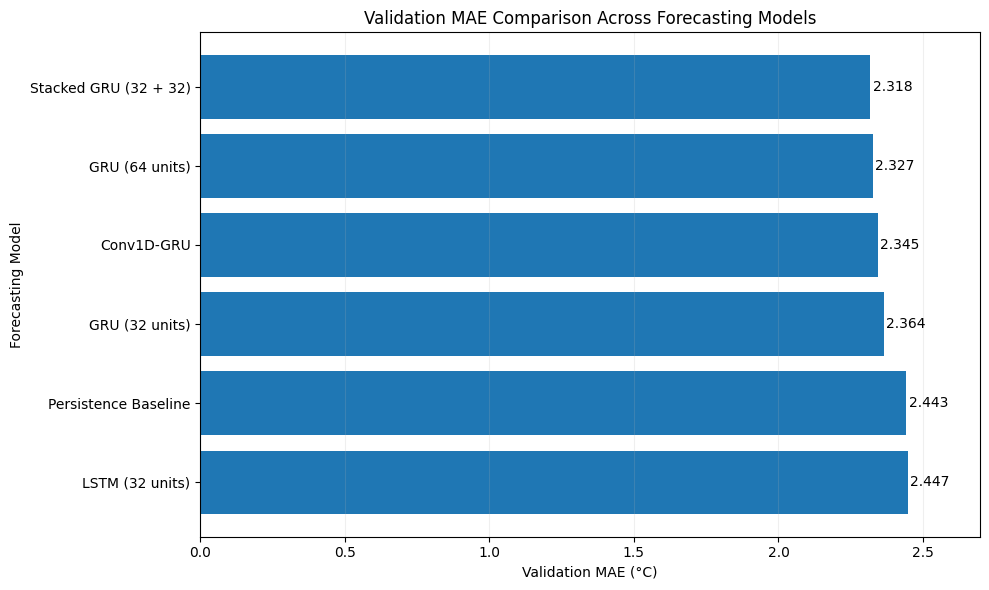

In [22]:

# Step 10A: Final Model Performance Comparison

# Collect validation MAE from all forecasting models
model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "GRU (32 units)",
        "GRU (64 units)",
        "Stacked GRU (32 + 32)",
        "LSTM (32 units)",
        "Conv1D-GRU"
    ],
    "Validation MAE (°C)": [
        baseline_validation_mae,
        best_gru_validation_mae,
        best_gru_64_validation_mae,
        best_stacked_gru_validation_mae,
        best_lstm_32_validation_mae,
        best_conv_gru_validation_mae
    ]
})

# Sort models by forecasting accuracy
model_comparison = model_comparison.sort_values(
    by="Validation MAE (°C)"
).reset_index(drop=True)

# Display the comparison table
display(model_comparison.round(3))

# Create the final comparison graph
plt.figure(figsize=(10, 6))

bars = plt.barh(
    model_comparison["Model"],
    model_comparison["Validation MAE (°C)"]
)

plt.gca().invert_yaxis()

for bar, score in zip(
    bars,
    model_comparison["Validation MAE (°C)"]
):
    plt.text(
        score + 0.008,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.3f}",
        va="center"
    )

plt.xlabel("Validation MAE (°C)")
plt.ylabel("Forecasting Model")
plt.title("Validation MAE Comparison Across Forecasting Models")
plt.xlim(0, model_comparison["Validation MAE (°C)"].max() + 0.25)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


### Overall Model Comparison

The comparison shows that the stacked GRU achieved the lowest validation MAE of **2.318°C**, followed closely by the 64-unit GRU at 2.327°C. The Conv1D-GRU model also performed better than the baseline, while the 32-unit LSTM had the highest validation error among the models tested.

These results suggest that increasing the number of GRU units and stacking recurrent layers can improve forecasting accuracy, although the improvements were relatively small. Adding a Conv1D layer did not outperform the stacked GRU in this experiment.

Based on validation MAE, the stacked GRU was selected as the best model for final evaluation on the held-out test dataset.

## 11. Final Model Evaluation

The stacked GRU model was selected for final evaluation because it achieved the lowest validation MAE among the tested models. The model is evaluated on the held-out test dataset to assess its forecasting accuracy on unseen weather observations.

The test dataset was not used during model training or model selection, providing an independent assessment of the selected model's performance.

In [23]:

# Step 11A: Evaluate the Best Model on Test Data

# Evaluate the selected stacked GRU model
stacked_gru_test_loss, stacked_gru_test_mae = (
    stacked_gru_model.evaluate(
        testing_series,
        verbose=1
    )
)

print(
    f"Stacked GRU Test MAE: "
    f"{stacked_gru_test_mae:.3f} °C"
)


408/408 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - loss: 10.1716 - mae: 2.4869
Stacked GRU Test MAE: 2.487 °C


### Test Results and Interpretation

The stacked GRU model achieved a test MAE of **2.487°C**, compared with its best validation MAE of 2.318°C. This means that, on average, its temperature predictions differed from the actual values by approximately 2.49°C on the held-out test dataset.

The test MAE was slightly higher than the validation MAE, indicating that forecasting accuracy varied between the two datasets. However, the model was able to make predictions on unseen weather observations without being trained on the test data.

These results provide an independent assessment of the stacked GRU model's forecasting performance.

In [24]:

# Step 11B: Evaluate the Persistence Baseline on Test Data

baseline_test_mae = calculate_baseline_mae(testing_series)

print(f"Baseline Test MAE: {baseline_test_mae:.3f} °C")
print(f"Stacked GRU Test MAE: {stacked_gru_test_mae:.3f} °C")


Baseline Test MAE: 2.620 °C
Stacked GRU Test MAE: 2.487 °C


### Final Test Performance Comparison

The persistence baseline achieved a test MAE of **2.620°C**, while the selected stacked GRU model achieved **2.487°C**. This represents a reduction of 0.133°C, or approximately 5.1%, in average prediction error.

The results show that the stacked GRU provided more accurate temperature forecasts than the baseline on the held-out test dataset. Although its test MAE was higher than its validation MAE, the model demonstrated an improvement over the simple persistence approach.

Overall, the stacked GRU was the best model based on validation performance and successfully improved forecasting accuracy over the baseline during final testing.

## 12. Visualization of Test Predictions

To further examine the forecasting performance of the selected stacked GRU model, actual temperatures are compared with predicted temperatures from the held-out test dataset. This visualization helps illustrate how closely the model follows temperature changes over time.

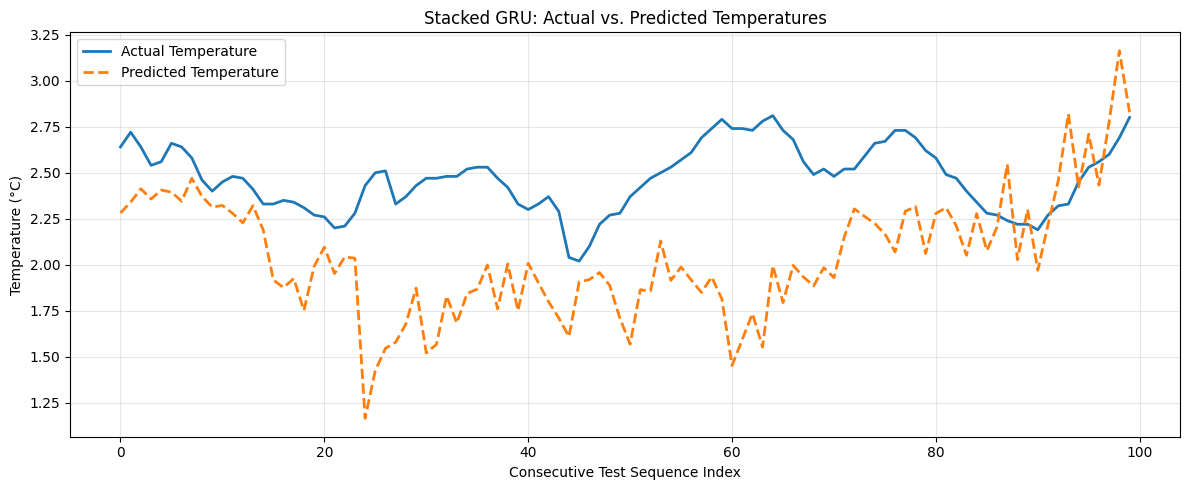

In [34]:

# Step 12A: Actual vs. Predicted Temperatures

# Select one batch from the test dataset
for test_inputs, test_targets in testing_series.take(1):
    actual_temperatures = test_targets.numpy()
    predicted_temperatures = stacked_gru_model.predict(
        test_inputs,
        verbose=0
    ).flatten()

# Plot the first 100 predictions
plt.figure(figsize=(12, 5))

plt.plot(
    actual_temperatures[:100],
    label="Actual Temperature",
    linewidth=2
)

plt.plot(
    predicted_temperatures[:100],
    label="Predicted Temperature",
    linestyle="--",
    linewidth=2
)

plt.title("Stacked GRU: Actual vs. Predicted Temperatures")
plt.xlabel("Consecutive Test Sequence Index")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation of Actual vs. Predicted Temperatures

The graph compares actual temperatures with predictions from the stacked GRU model for 100 consecutive test sequences. The predicted values follow some of the overall temperature changes, although differences are visible throughout the selected period.

The model tends to underestimate temperatures in several parts of this sample, particularly in the middle section. This indicates that the model captures useful patterns but does not predict every temperature fluctuation accurately.

Despite these differences, the stacked GRU achieved a lower overall test MAE (2.487°C) than the persistence baseline (2.620°C), showing an improvement in forecasting performance across the full test dataset.

### Final Test MAE Comparison

The following graph compares the prediction errors of the persistence baseline and the selected stacked GRU model on the held-out test dataset. Lower MAE values indicate more accurate temperature forecasts.

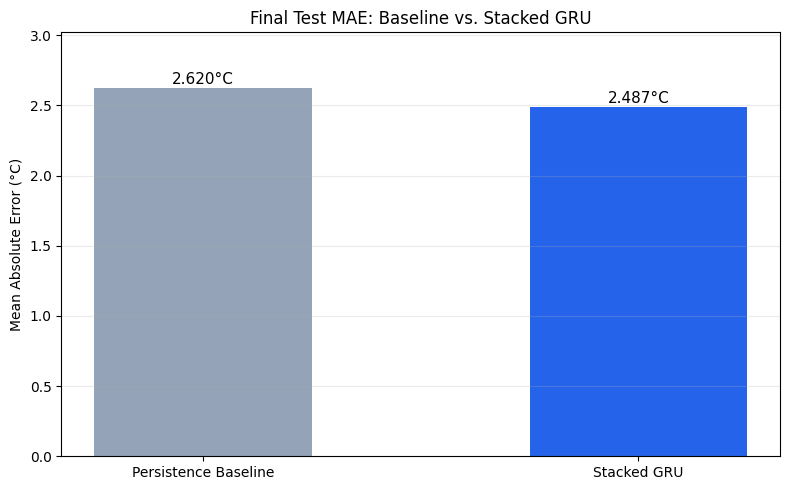

In [26]:

# Step 12B: Compare Final Test MAE

model_names = ["Persistence Baseline", "Stacked GRU"]
test_mae_values = [baseline_test_mae, stacked_gru_test_mae]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    model_names,
    test_mae_values,
    color=["#94A3B8", "#2563EB"],
    width=0.5
)

for bar, value in zip(bars, test_mae_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.03,
        f"{value:.3f}°C",
        ha="center",
        fontsize=11
    )

plt.title("Final Test MAE: Baseline vs. Stacked GRU")
plt.ylabel("Mean Absolute Error (°C)")
plt.ylim(0, max(test_mae_values) + 0.4)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### Interpretation of Final Test MAE Comparison

The graph shows that the stacked GRU achieved a test MAE of 2.487°C, compared with 2.620°C for the persistence baseline.

This means the stacked GRU reduced the average absolute prediction error by approximately 5.1%. Although the improvement was relatively small, the results show that the model was able to learn useful patterns from previous weather observations and make better predictions than simply using the last recorded temperature.

## 13. Conclusion

In this assignment, I explored different deep-learning models to predict temperature 24 hours ahead using the Jena Climate dataset. I tested GRU models with different numbers of units, a stacked GRU, an LSTM model, and a combination of Conv1D and GRU layers.

The stacked GRU performed best, achieving the lowest validation MAE of 2.318°C. Increasing the number of GRU units also improved performance, but the difference was relatively small. The LSTM and Conv1D-GRU models did not perform as well as the stacked GRU in this experiment.

After selecting the best model, I evaluated it using the test dataset. The stacked GRU achieved a test MAE of 2.487°C, compared with 2.620°C for the persistence baseline. This represents approximately a 5.1% reduction in average absolute prediction error.

I also noticed that some models showed signs of overfitting when their training errors continued decreasing while validation errors increased. Using early stopping helped retain the model weights from the best-performing epoch.

Overall, this assignment helped me understand how different recurrent neural network architectures can be applied to time-series forecasting. I also learned that adding more layers or units does not always lead to a large improvement in performance. In future experiments, I would like to explore dropout and different sequence lengths to see whether they can further improve the predictions.

### Dataset Acknowledgment

This assignment uses the Jena Climate dataset, which contains historical weather measurements recorded in Jena, Germany. The dataset was used to train and evaluate different neural network models for temperature forecasting.

The analysis, model comparisons, and conclusions are based on the experiments presented in this notebook.

**Dataset Source:** Max Planck Institute for Biogeochemistry. (n.d.). *Jena Climate dataset*. https://www.bgc-jena.mpg.de/wetter/

In [35]:
# Export the completed notebook as HTML
from google.colab import files

uploaded = files.upload()

notebook_filename = next(iter(uploaded))

!jupyter nbconvert --to html "{notebook_filename}" --output "Assignment_3_Time_Series.html"

files.download("Assignment_3_Time_Series.html")


Saving Untitled3.ipynb to Untitled3 (2).ipynb
[NbConvertApp] Converting notebook Untitled3 (2).ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 10 image(s).
[NbConvertApp] Writing 1036076 bytes to Assignment_3_Time_Series.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>